# Detección de URLs de *phishing* — Análisis exploratorio de datos
### Proyecto — Introducción al Machine Learning (Modelos II)
**Dataset:** PhiUSIIL Phishing URL Dataset (Prasad & Chandra, 2024) — UCI ML Repository (id=967)

Este notebook corresponde a la sección **Descripción del problema (Parte II)** del informe. Contiene
el análisis exploratorio (EDA): dimensiones, tipos de variables, valores faltantes, duplicados,
balance de clases, cardinalidad de las variables categóricas, correlación con la etiqueta y la
estrategia de codificación propuesta.

> El notebook y el informe comparten las mismas secciones, como exige la guía del proyecto.

## 0. Configuración e importación de librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 60)
plt.rcParams['figure.dpi'] = 110
RANDOM_STATE = 42

## 1. Carga de los datos

El dataset se puede cargar de forma reproducible con el paquete `ucimlrepo` (descarga directa desde UCI).
Si no hay conexión, se usa como alternativa el archivo `PhiUSIIL_Phishing_URL_Dataset.csv` colocado en la
carpeta `data/`.

In [2]:
try:
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=967)
    df = pd.concat([ds.data.features, ds.data.targets], axis=1)
    print('Datos cargados desde UCI (ucimlrepo).')
except Exception as e:
    print('No se pudo usar ucimlrepo (', e, '). Se carga el CSV local.')
    df = pd.read_csv('data/PhiUSIIL_Phishing_URL_Dataset.csv')

# La ficha de UCI indica que la columna FILENAME (si está presente) puede ignorarse.
df = df.drop(columns=[c for c in ['FILENAME'] if c in df.columns])
df.head()

No se pudo usar ucimlrepo ( No module named 'ucimlrepo' ). Se carga el CSV local.


,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,3,1,0,0,0.0,18,0.581,0,0.0,0,0,0,1,0.032,1,558,9381,1,à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µ...,0.000000,0.000000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,2,1,0,0,0.0,9,0.391,0,0.0,0,0,0,2,0.087,1,618,9381,1,johannes gutenberg-universitÃ¤t mainz,55.555556,55.555556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,2,2,0,0,0.0,15,0.517,0,0.0,0,0,0,2,0.069,1,467,682,1,voice fm southampton,46.666667,46.666667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1
3,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,3,1,0,0,0.0,13,0.500,0,0.0,0,0,0,1,0.038,1,6356,26824,1,home page: seminars in fetal and neonatal medi...,0.000000,0.000000,0,1,1,0,0,0,1,12,0,1,1,1,0,0,1,1,1,3,27,15,22,1,31,1
4,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,3,1,0,0,0.0,20,0.606,0,0.0,0,0,0,1,0.030,1,6089,28404,1,fundaciÃ³n rewilding argentina,100.000000,100.000000,0,1,1,1,1,1,0,2,0,1,1,1,0,1,1,0,1,244,15,34,72,1,85,1


## 2. Dimensiones y tipos de variables

In [3]:
print(f'Número de muestras (filas): {df.shape[0]:,}')
print(f'Número de variables (columnas): {df.shape[1]}')
print(f'  - Características (features): {df.shape[1]-1}')
print(f'  - Variable objetivo: label')
print()
print('Conteo por tipo de dato:')
print(df.dtypes.astype(str).value_counts())

Número de muestras (filas): 235,795
Número de variables (columnas): 55
  - Características (features): 54
  - Variable objetivo: label

Conteo por tipo de dato:
int64      41
float64    10
str         4
Name: count, dtype: int64


In [4]:
# Clasificación de las variables
text_cols = df.select_dtypes(include=['object','string']).columns.tolist()
num_cols  = df.select_dtypes(include=[np.number]).columns.drop('label').tolist()
binary_cols = [c for c in num_cols if set(df[c].dropna().unique()) <= {0,1}]
print(f'Variables de texto/categóricas ({len(text_cols)}): {text_cols}')
print(f'Variables numéricas ({len(num_cols)}): de ellas {len(binary_cols)} son binarias (0/1)')

Variables de texto/categóricas (4): ['URL', 'Domain', 'TLD', 'Title']
Variables numéricas (50): de ellas 19 son binarias (0/1)


### Significado de las variables
El dataset contiene tres grupos de características (ver ficha de UCI y el artículo original):

| Grupo | Ejemplos | Descripción |
|---|---|---|
| **Basadas en la URL** | `URLLength`, `DomainLength`, `NoOfSubDomain`, `NoOfDegitsInURL`, `SpacialCharRatioInURL`, `IsDomainIP` | Métricas léxicas y estructurales extraídas de la cadena de la URL. |
| **Derivadas / de similitud** | `URLSimilarityIndex`, `CharContinuationRate`, `TLDLegitimateProb`, `URLCharProb` | Variables calculadas por los autores a partir de otras (índice de similitud, probabilidades). |
| **Basadas en el código HTML** | `LineOfCode`, `HasTitle`, `HasFavicon`, `IsResponsive`, `HasPasswordField`, `NoOfJS`, `HasCopyrightInfo`, `HasSocialNet` | Atributos extraídos del código fuente de la página. |

Variables de identificación/texto: `URL`, `Domain`, `TLD`, `Title`.
**Etiqueta `label`:** 1 = URL legítima, 0 = URL de *phishing*.

## 3. Valores faltantes

In [5]:
na = df.isna().sum()
print('Total de valores faltantes en todo el dataset:', int(na.sum()))
print('Columnas con faltantes:', na[na>0].to_dict() or 'ninguna')

Total de valores faltantes en todo el dataset: 0
Columnas con faltantes: ninguna


El dataset **no presenta valores faltantes**, por lo que no se requiere una estrategia de imputación
(`SimpleImputer`/`KNNImputer`). De haberlos, se mediría primero el porcentaje con `df.isna().mean()`
y se decidiría entre eliminación o imputación, como se vio en la sesión de preprocesamiento del curso.

## 4. Registros duplicados

In [6]:
print('Filas completamente duplicadas:', int(df.duplicated().sum()))
feat_only = [c for c in df.columns if c not in ('URL','Domain','label')]
print('Filas con características idénticas (ignorando URL/Domain/label):', int(df.duplicated(subset=feat_only).sum()))

Filas completamente duplicadas: 0


Filas con características idénticas (ignorando URL/Domain/label): 120


## 5. Balance de clases

label=0 (phishing): 100,945 (42.81%)
label=1 (legítima): 134,850 (57.19%)


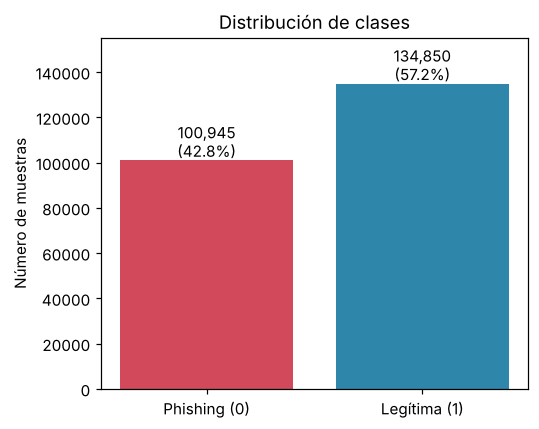

In [7]:
vc = df['label'].value_counts().sort_index()
for k in vc.index:
    print(f'label={k} ({"phishing" if k==0 else "legítima"}): {vc[k]:,} ({100*vc[k]/len(df):.2f}%)')

plt.figure(figsize=(5,4))
b = plt.bar(['Phishing (0)','Legítima (1)'], [vc[0], vc[1]], color=['#d1495b','#2e86ab'])
for bar,v in zip(b, [vc[0], vc[1]]):
    plt.text(bar.get_x()+bar.get_width()/2, v, f'{v:,}\n({100*v/len(df):.1f}%)', ha='center', va='bottom')
plt.ylabel('Número de muestras'); plt.title('Distribución de clases'); plt.ylim(0, vc.max()*1.15)
plt.tight_layout(); plt.show()

El problema está **moderadamente balanceado** (57.2% legítimas / 42.8% phishing). No se requieren
técnicas agresivas de remuestreo (SMOTE), pero por buena práctica la partición de datos se hará de forma
**estratificada** para conservar la proporción de clases, y se reportarán métricas robustas al desbalance
(F1, *balanced accuracy*, MCC) además de la exactitud.

## 6. Cardinalidad de las variables de texto/categóricas

URL: 235,370 valores únicos
Domain: 220,086 valores únicos
Title: 197,874 valores únicos
TLD: 695 valores únicos


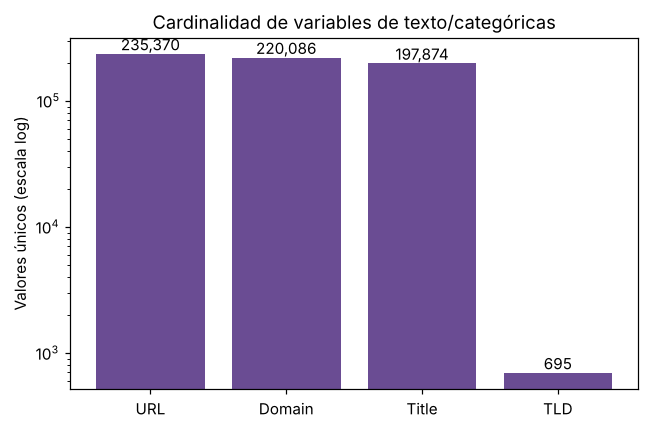


TLDs más frecuentes:
TLD
com    112554
org     18793
net      7097
app      6508
uk       6395
co       5422
io       4201
de       3996
ru       3875
au       2979
Name: count, dtype: int64


In [8]:
card = {c: df[c].nunique() for c in ['URL','Domain','Title','TLD'] if c in df.columns}
for k,v in card.items(): print(f'{k}: {v:,} valores únicos')

plt.figure(figsize=(6,4))
plt.bar(card.keys(), card.values(), color='#6a4c93', log=True)
for i,(k,v) in enumerate(card.items()):
    plt.text(i, v, f'{v:,}', ha='center', va='bottom')
plt.ylabel('Valores únicos (escala log)'); plt.title('Cardinalidad de variables de texto/categóricas')
plt.tight_layout(); plt.show()

print('\nTLDs más frecuentes:')
print(df['TLD'].value_counts().head(10))

**Implicación para la codificación.** `URL`, `Domain` y `Title` tienen cardinalidad casi igual al número
de muestras: son prácticamente identificadores/texto libre y **no se codifican con one-hot**. Se descartan como
variables directas (su información ya está resumida en las características numéricas) o se reservan para una
posible extracción de características de texto (NLP) en fases posteriores.

`TLD` tiene 695 categorías sin orden: un one-hot generaría cientos de columnas dispersas. Las alternativas
vistas/razonables son: (i) usar la variable numérica `TLDLegitimateProb`, que ya codifica el TLD como una
probabilidad; (ii) *frequency/target encoding*; o (iii) agrupar los TLD poco frecuentes en una categoría
`otros` y aplicar one-hot a los más comunes.

## 7. Estadísticos de variables numéricas clave

In [9]:
key = ['URLLength','DomainLength','URLSimilarityIndex','CharContinuationRate',
       'TLDLegitimateProb','URLCharProb','NoOfImage','LineOfCode']
df[[c for c in key if c in df.columns]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.573,41.314,13.000,23.000,27.000,34.000,6097.000
DomainLength,235795.0,21.470,9.151,4.000,16.000,20.000,24.000,110.000
URLSimilarityIndex,235795.0,78.431,28.976,0.156,57.025,100.000,100.000,100.000
CharContinuationRate,235795.0,0.846,0.217,0.000,0.680,1.000,1.000,1.000
TLDLegitimateProb,235795.0,0.260,0.252,0.000,0.006,0.080,0.523,0.523
URLCharProb,235795.0,0.056,0.011,0.001,0.051,0.058,0.063,0.091
NoOfImage,235795.0,26.076,79.412,0.000,0.000,8.000,29.000,8956.000
LineOfCode,235795.0,1141.900,3419.951,2.000,18.000,429.000,1277.000,442666.000


Varias variables numéricas tienen escalas muy distintas y colas largas (p. ej. `LineOfCode` y `NoOfImage`
con máximos de cientos de miles). Para los modelos sensibles a la escala (regresión logística, KNN, SVM, redes
neuronales) se aplicará **estandarización** (`StandardScaler`) o normalización (`MinMaxScaler`), ajustada
únicamente sobre el conjunto de entrenamiento para evitar fuga de información.

## 8. Relación de las características con la etiqueta

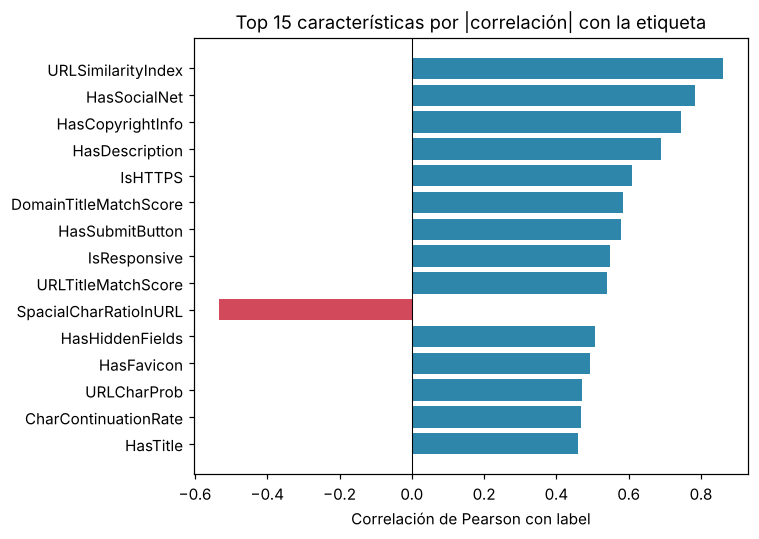

URLSimilarityIndex       0.860
HasSocialNet             0.784
HasCopyrightInfo         0.743
HasDescription           0.690
IsHTTPS                  0.609
DomainTitleMatchScore    0.585
HasSubmitButton          0.579
IsResponsive             0.549
URLTitleMatchScore       0.539
SpacialCharRatioInURL   -0.534
HasHiddenFields          0.508
HasFavicon               0.494
URLCharProb              0.470
CharContinuationRate     0.468
HasTitle                 0.460
dtype: float64

In [10]:
corr = df[num_cols].corrwith(df['label']).sort_values(key=lambda s: s.abs(), ascending=False)
top = corr.head(15)
plt.figure(figsize=(7,5))
colors = ['#2e86ab' if v>0 else '#d1495b' for v in top.values]
plt.barh(top.index[::-1], top.values[::-1], color=colors[::-1])
plt.axvline(0, color='k', lw=0.7); plt.xlabel('Correlación de Pearson con label')
plt.title('Top 15 características por |correlación| con la etiqueta')
plt.tight_layout(); plt.show()
top.round(3)

### 8.1 Distribuciones por clase de algunas variables

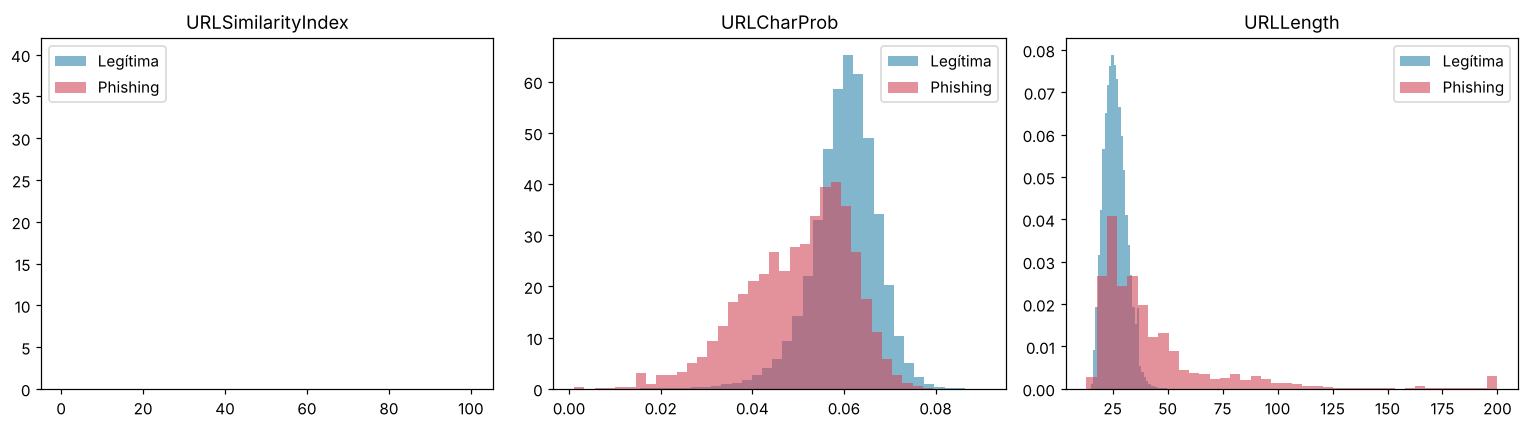

In [11]:
fig, axes = plt.subplots(1,3, figsize=(14,4))
for ax, col in zip(axes, ['URLSimilarityIndex','URLCharProb','URLLength']):
    for lab,c,name in [(1,'#2e86ab','Legítima'),(0,'#d1495b','Phishing')]:
        data = df[df['label']==lab][col]
        if col=='URLLength': data = data.clip(upper=200)
        ax.hist(data, bins=40, alpha=0.6, color=c, label=name, density=True)
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()

### 8.2 Advertencia: posible fuga de información (*data leakage*)

In [12]:
# IsHTTPS vs label
print(pd.crosstab(df['IsHTTPS'], df['label'], margins=True))
print()
print('De las URLs con IsHTTPS=1, porcentaje legítimas:',
      round(100*df[df.IsHTTPS==1]['label'].mean(),2), '%')

label         0       1     All
IsHTTPS                        
0         51256       0   51256
1         49689  134850  184539
All      100945  134850  235795

De las URLs con IsHTTPS=1, porcentaje legítimas: 73.07 %


Dos señales merecen atención antes del modelado:

- **`URLSimilarityIndex`** tiene una correlación de ~0.86 con la etiqueta.
- **`IsHTTPS`**: *todas* las URLs con HTTPS en este dataset están etiquetadas como legítimas (la clase phishing
  solo aparece cuando `IsHTTPS=0`).

Esto puede inflar artificialmente el desempeño (varios modelos alcanzan >99% en la literatura). En las fases de
modelado y validación se evaluará el impacto de estas variables (p. ej. midiendo el desempeño sin ellas) para
asegurar que el modelo generaliza y no está memorizando un atajo del proceso de construcción del dataset.

## 9. Conclusiones del EDA

- **235.795 muestras** y **54 características** (+ `label`); sin valores faltantes ni filas duplicadas.
- Problema de **clasificación binaria supervisada**, moderadamente balanceado (57.2% / 42.8%).
- Cuatro variables de texto (`URL`, `Domain`, `Title`, `TLD`) de alta cardinalidad → no aptas para one-hot
  directo; se usarán las variables numéricas derivadas y/o codificación por frecuencia para `TLD`.
- Escalas heterogéneas → **estandarización** para modelos sensibles a la escala.
- Partición **estratificada** y métricas robustas al desbalance (F1, BACC, MCC) además de exactitud y AUC.
- Señales de posible *data leakage* (`URLSimilarityIndex`, `IsHTTPS`) a vigilar en el modelado.